# 광섬유 시뮬레이션 — 입력 → 출력 → 예시 → Mesh 검증

**G.654.E / G.657.A1 통합 실행형 보고서 · 2026-10-19**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kimheeseo/LSCNS/blob/main/COMSOL/fiber_simulation_guide/Fiber_Input_Output_Examples.ipynb)

`런타임 → 모두 실행`으로 두 광섬유의 기본 예시, 입력 변경 예시, radial/2D Mesh 비교와 외부 영역 검사를 실제 재계산합니다. **기본 예시의 코드 실행 출력과 그림도 저장**했습니다.

이 도구는 가정한 원형 step-index 단면의 약유도 스칼라 LP01 계산기입니다. 실제 제조사 굴절률 구조 또는 COMSOL 결과의 독립 검증은 아닙니다.


## 1. 어떤 값을 입력하는가?

| 입력 | 단위·의미 | 사용 방법 |
|---|---|---|
| 분석 파장 | nm | 해당 파장에서 모드·MFD·Aeff·D를 계산 |
| 코어 반경 a | µm, 지름 아님 | 기본값 G.654.E 5.5, G.657.A1 4.1: **가정값** |
| Δn | n_core−n_clad, 절대 차이 | 직접 계산 모드에서 사용 |
| 목표 MFD | µm, Petermann-II | 보정 모드에서만 입력; Δn을 맞춤 |
| MFD 기준 파장 | G.654.E 1550 / G.657.A1 1310 nm | 분석 파장을 바꿔도 기준은 유지 |
| 클래딩 굴절률 | 실리카 Sellmeier로 자동 계산 | n_core=n_clad+일정 Δn 가정 |
| n2 | m²/W | gamma용 **가정값**, 직접 변경 가능 |
| Radial 요소 수 / 클래딩 비율 | 코어 요소 수와 클래딩 요소 수의 비 | Mesh 세분화 검사 |
| 2D N×N / 외곽 반폭 | 홀수 N / µm | 계산영역의 실제 전체 폭은 반폭의 두 배 |
| Radial 외곽 반경 | µm | Mesh 수와 별도로 경계 영향 검사 |

**직접 계산:** a·Δn 입력 → MFD가 출력됩니다. **MFD 보정:** a·목표 MFD 입력 → Δn이 보정됩니다. 보정한 MFD를 독립적으로 예측한 값이라고 보고하지 않습니다.


## 2. 어떤 결과가 나오는가?

| 출력 | 의미·단위 | 주의 |
|---|---|---|
| n_core / n_clad / V / n_eff | 굴절률, 정규화 주파수, 유효굴절률 | LP01 기준 모델 |
| 2D 모드 세기 | 상대 | Bessel 이론 그림과 실제 FEM 그림을 구분 |
| MFD_PII / MFD_2nd | µm | Petermann-II와 중심 2차 모멘트 정의 구분 |
| Aeff | µm² | 장분포에서 직접 적분; MFD 원 면적과 일반적으로 다름 |
| D / S | ps/(nm·km) / ps/(nm²·km) | 이론 n_eff의 파장 미분, 실제 도핑 분산 미사용 |
| λ0 / S0 | nm / ps/(nm²·km) | 지원 파장 구간에서 영점을 찾은 경우만 표시; 미해결은 빈 값 |
| gamma | 1/(W·km) | 입력 n2와 예측 Aeff를 사용한 파생값 |
| FEM 오차 / 잔차 | 절대오차·상대오차(%) | 같은 가상 단면의 Bessel 해와 비교 |
| Mesh·영역 표 | 설정과 계산값 | Mesh를 늘렸다는 사실만으로 정확도 보장 불가 |

**계산하지 않는 값:** 실제 감쇠, 굽힘 손실, 케이블 컷오프 인증, PMD·복굴절, 전체 전송거리·BER·GN 전송성능. 별도 물리 모델이나 측정이 필요합니다.


In [1]:
# @title 3. 환경 설정
import os,sys,json,uuid,zipfile,platform
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
from IPython.display import display,FileLink
get_ipython().run_line_magic('matplotlib','inline')
RESULT_DIR=Path('Fiber_Input_Output_Results')/uuid.uuid4().hex[:12]
RESULT_DIR.mkdir(parents=True,exist_ok=False)
print('Python',sys.version.split()[0],'NumPy',np.__version__,'SciPy',scipy.__version__)


No event loop hook running.
Python 3.12.14 NumPy 2.3.5 SciPy 1.17.0


In [2]:
# @title 4. 입력값 — 이 셀을 바꾼 뒤 아래 셀들을 다시 실행
fit_delta_n_from_mfd = True # @param {type:"boolean"}
g654e_wavelength_nm = 1550.0 # @param {type:"number"}
g654e_core_radius_um = 5.5 # @param {type:"number"}
g654e_target_mfd_um = 12.5 # @param {type:"number"}
g654e_manual_delta_n = 0.0034785793846155 # @param {type:"number"}
g654e_n2_m2_W = 2.2e-20 # @param {type:"number"}
g657a1_wavelength_nm = 1310.0 # @param {type:"number"}
g657a1_core_radius_um = 4.1 # @param {type:"number"}
g657a1_target_mfd_um = 9.2 # @param {type:"number"}
g657a1_manual_delta_n = 0.0046215295453259 # @param {type:"number"}
g657a1_n2_m2_W = 2.6e-20 # @param {type:"number"}
radial_core_mesh_text = "40,80,160,320" # @param {type:"string"}
cladding_to_core_element_ratio = 4 # @param {type:"integer"}
radial_outer_radius_um = 40.0 # @param {type:"number"}
mesh_2d_text = "61,81,121,161" # @param {type:"string"}
box_2d_halfwidth_um = 24.0 # @param {type:"number"}
run_2d_fem = True # @param {type:"boolean"}
# MFD 기준 파장은 공개 자료의 값에 대응하도록 고정합니다.
MFD_REFERENCE_NM={'G.654.E':1550.,'G.657.A1':1310.}


In [3]:
# @title 5. 자체 포함 FEM 엔진 (펼쳐보기)
"""Independent repeatable verification of the M7 scalar Step-index assumptions.
Numerical radial P1 FEM is directly transcribed from COMSOL/waveoptics_m7/src/radial_fem.py
(with equivalent input class). LP01 Bessel oracle is transcribed from fiber_modes.py.
This DOES NOT simulate or validate the actual undisclosed G.657.A1 index profile.
"""
from __future__ import annotations
from dataclasses import dataclass, replace
import numpy as np
from scipy.special import j0,j1,k0 as K0,k1 as K1
from scipy.optimize import brentq, root, minimize_scalar
from scipy.integrate import quad
from numpy.polynomial.legendre import leggauss
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import eigsh
import matplotlib.pyplot as plt
import json
from pathlib import Path
C0=299792458.
SB=(.6961663,.4079426,.8974794);SC=(.0684043**2,.1162414**2,9.896161**2)
def silica_index(w):
 w=float(w)
 return float(np.sqrt(1+sum(b*w*w/(w*w-c) for b,c in zip(SB,SC))))
@dataclass(frozen=True)
class Fiber:
 wavelength_um:float=1.31
 radius_um:float=4.1
 delta_n:float=.003
 domain_halfwidth_um:float=35.
 n_cladding:float|None=None
 @property
 def clad(self):return silica_index(self.wavelength_um) if self.n_cladding is None else self.n_cladding
 @property
 def core(self):return self.clad+self.delta_n
 @property
 def v(self):return 2*np.pi*self.radius_um/self.wavelength_um*np.sqrt(self.core**2-self.clad**2)
def lp01_analytic(f):
 v=f.v
 if not 0<v<2.404825557695772:raise ValueError(f"LP01 oracle limited V<2.405: V={v}")
 def eq(u):
  w=np.sqrt(v*v-u*u)
  return u*j1(u)/j0(u)-w*K1(w)/K0(w)
 u=brentq(eq,max(v*1e-6,1e-8),v*(1-1e-10),xtol=2e-13)
 w=np.sqrt(v*v-u*u)
 ne=float(np.sqrt((2*np.pi*f.core/f.wavelength_um)**2-(u/f.radius_um)**2)*f.wavelength_um/(2*np.pi))
 return dict(V=float(v),u=float(u),w=float(w),n_eff=ne)
def radial_lp01_aeff(f):
 a=lp01_analytic(f);u,w=a['u'],a['w'];radius=f.radius_um
 def shape(t):return j0(u*t)/j0(u) if t<=1 else K0(w*t)/K0(w)
 def d_shape(t):return -u*j1(u*t)/j0(u) if t<=1 else -w*K1(w*t)/K0(w)
 def integrate(power,moment,deriv=False):
  s=d_shape if deriv else shape
  fun=lambda t:s(t)**power*t**moment
  return quad(fun,0,1,epsabs=1e-11,epsrel=1e-10)[0]+quad(fun,1,np.inf,epsabs=1e-11,epsrel=1e-10)[0]
 total=2*np.pi*radius**2*integrate(2,1)
 four=2*np.pi*radius**2*integrate(4,1)
 mom=2*np.pi*radius**4*integrate(2,3)/total
 # Petermann-II: MFD=2 sqrt(2 * \int E^2 r dr / \int (dE/dr)^2 r dr).
 # With t=r/a, denominator has no a^2 and numerator has a^2.
 petermann=2*radius*np.sqrt(2*integrate(2,1)/integrate(2,1,deriv=True))
 return dict(Aeff_um2=float(total**2/four),MFD_2nd_um=float(2*np.sqrt(2*mom)), MFD_petermann_ii_um=float(petermann))
def solve_radial(fiber, core_elements=160, clad_elements=640, outer_radius_um=None):
 outer = fiber.domain_halfwidth_um if outer_radius_um is None else float(outer_radius_um)
 a=fiber.radius_um
 r=np.r_[np.linspace(0,a,core_elements+1),np.linspace(a,outer,clad_elements+1)[1:]]
 x,w=leggauss(4);t=(x+1)/2;phi=np.stack((1-t,t),axis=1)
 h=np.diff(r);rq=r[:-1,None]+h[:,None]*t;weights=h[:,None]*w/2
 mass=np.einsum('eq,qi,qj->eij',weights*rq,phi,phi)
 stiff=((r[1:]**2-r[:-1]**2)/(2*h**2))[:,None,None]*np.array([[1.,-1.],[-1.,1.]])
 indices=np.r_[np.full(core_elements,fiber.core),np.full(clad_elements,fiber.clad)]
 k0=2*np.pi/fiber.wavelength_um
 local=k0**2*indices[:,None,None]**2*mass-stiff
 edges=np.stack((np.arange(len(h)),np.arange(len(h))+1),axis=1)
 rows=np.broadcast_to(edges[:,:,None],local.shape).ravel()
 cols=np.broadcast_to(edges[:,None,:],local.shape).ravel()
 def matrix(v):return coo_matrix((v.ravel(),(rows,cols)),shape=(len(r),len(r))).tocsr()[:-1,:-1]
 A,M=matrix(local),matrix(mass)
 val,vec=eigsh(A,k=1,M=M,sigma=(k0*fiber.core)**2,which='LM',v0=np.ones(len(r)-1),tol=1e-11)
 beta2=float(val[0]);q=vec[:,0]
 residual=np.linalg.norm(A@q-beta2*(M@q))/np.linalg.norm(beta2*(M@q))
 field=np.r_[q,0.]
 if field[0]<0:field=-field
 fieldq=field[edges]@phi.T;intensity=fieldq**2
 wt=2*np.pi*weights*rq;power=np.sum(wt*intensity)
 aeff=power**2/np.sum(wt*intensity**2)
 moment=np.sum(wt*intensity*rq**2)/power
 neff=np.sqrt(beta2)/k0 if beta2>0 else float('nan')
 return dict(n_eff=float(neff),Aeff_um2=float(aeff),MFD_2nd_um=float(2*np.sqrt(2*moment)),residual=float(residual),guided=bool(fiber.clad<neff<fiber.core),outer_radius_um=outer,core_elements=core_elements,clad_elements=clad_elements, radius_um=r,field=field/np.sqrt(power))
def dispersion_lp01(f,step=.003):
 def ne(x):return lp01_analytic(replace(f,wavelength_um=float(x)))['n_eff']
 w=f.wavelength_um;h=step
 d2=(-ne(w+2*h)+16*ne(w+h)-30*ne(w)+16*ne(w-h)-ne(w-2*h))/(12*h*h)
 return float(-(w/C0)*1e12*d2)

def grid(n,h):
 if not isinstance(n,(int,np.integer)) or isinstance(n,bool) or n<15 or n%2!=1:raise ValueError('odd mesh count>=15')
 if not np.isfinite(h) or h<=0:raise ValueError('positive finite halfwidth')
 xy=np.stack(np.meshgrid(np.linspace(-h,h,n),np.linspace(-h,h,n),indexing='xy'),-1).reshape(-1,2)
 i,j=np.meshgrid(np.arange(n-1),np.arange(n-1),indexing='xy');p=(j*n+i).ravel()
 tris=np.concatenate([np.stack([p,p+1,p+n+1],1),np.stack([p,p+n+1,p+n],1)]).astype(int)
 free=np.flatnonzero((np.abs(xy[:,0])<h-1e-9)&(np.abs(xy[:,1])<h-1e-9))
 return xy,tris,free
def assemble_fem(xy,tri,index):
 p=xy[tri];dx=p[:,1,0]-p[:,0,0];dy=p[:,1,1]-p[:,0,1];ex=p[:,2,0]-p[:,0,0];ey=p[:,2,1]-p[:,0,1]
 det=dx*ey-dy*ex
 if np.any(np.abs(det)<1e-14):raise ValueError('degenerate triangle')
 area=np.abs(det)/2
 gx=np.stack([p[:,1,1]-p[:,2,1],p[:,2,1]-p[:,0,1],p[:,0,1]-p[:,1,1]],1)/det[:,None]
 gy=np.stack([p[:,2,0]-p[:,1,0],p[:,0,0]-p[:,2,0],p[:,1,0]-p[:,0,0]],1)/det[:,None]
 K=area[:,None,None]*(gx[:,:,None]*gx[:,None,:]+gy[:,:,None]*gy[:,None,:])
 b=np.ones((3,3));np.fill_diagonal(b,2)
 M=area[:,None,None]*b[None,:,:]/12
 ni=np.asarray(index(p.mean(1)),float)
 if len(ni)!=len(area) or np.any(ni<=0):raise ValueError('invalid index')
 N=M*ni[:,None,None]**2
 rows=np.broadcast_to(tri[:,:,None],(len(tri),3,3)).ravel()
 cols=np.broadcast_to(tri[:,None,:],(len(tri),3,3)).ravel()
 def csr(v):return coo_matrix((v.ravel(),(rows,cols)),shape=(len(xy),len(xy))).tocsr()
 return csr(K),csr(M),csr(N)
def solve_modes(f,n=81,cores=None,modes=2):
 centers=[(0.,0.)] if cores is None else list(cores)
 c=np.asarray(centers,float)
 xy,tri,free=grid(n,f.domain_halfwidth_um)
 def index(points):
  r2=np.full(len(points),np.inf)
  for xx,yy in centers:r2=np.minimum(r2,(points[:,0]-xx)**2+(points[:,1]-yy)**2)
  return np.where(r2<=f.radius_um**2,f.core,f.clad)
 K,M,N=assemble_fem(xy,tri,index);k0=2*np.pi/f.wavelength_um;A=(k0*k0*N-K)[free][:,free];MM=M[free][:,free]
 vals,vectors=eigsh(A,k=modes,M=MM,sigma=(k0*f.core)**2+.02,which='LM',tol=1e-10,v0=np.random.default_rng(0).normal(size=len(free)))
 order=np.argsort(vals)[::-1];vals=vals[order];vectors=vectors[:,order]
 fields=np.zeros((len(xy),modes));fields[free,:]=vectors
 neff=np.sqrt(np.maximum(0,vals))/k0
 resid=[float(np.linalg.norm(A@vectors[:,i]-vals[i]*(MM@vectors[:,i]))/np.linalg.norm(vals[i]*(MM@vectors[:,i]))) for i in range(modes)]
 return dict(fiber=f,n=n,xy=xy,triangles=tri,free=free,mass=M,neff=neff,fields=fields,guided=(neff>f.clad)&(neff<f.core),residuals=resid,cores=centers)
def scalar_metrics(sol,k=0):
 b=np.array([[1/3,1/3,1/3],[.059715871789770,.470142064105115,.470142064105115],[.470142064105115,.059715871789770,.470142064105115],[.470142064105115,.470142064105115,.059715871789770],[.797426985353087,.101286507323456,.101286507323456],[.101286507323456,.797426985353087,.101286507323456],[.101286507323456,.101286507323456,.797426985353087]])
 weights=np.array([.225,.132394152788506,.132394152788506,.132394152788506,.125939180544827,.125939180544827,.125939180544827])
 tri=sol['triangles'];xyz=sol['xy'][tri];p=sol['fields'][tri,k]
 area=np.abs((xyz[:,1,0]-xyz[:,0,0])*(xyz[:,2,1]-xyz[:,0,1])-(xyz[:,2,0]-xyz[:,0,0])*(xyz[:,1,1]-xyz[:,0,1]))/2
 intensity=np.abs(p@b.T)**2;points=np.einsum('qi,tij->tqj',b,xyz)
 wt=area[:,None]*weights
 power=float(np.sum(wt*intensity));four=float(np.sum(wt*intensity**2))
 center=np.sum(wt[:,:,None]*intensity[:,:,None]*points,axis=(0,1))/power
 r2=np.sum((points-center)**2,axis=2);moment=np.sum(wt*intensity*r2)/power
 return dict(n_eff=float(sol['neff'][k]),Aeff_um2=power**2/four,MFD_2nd_um=float(2*np.sqrt(2*moment)),residual=float(sol['residuals'][k]),centroid_um=center.tolist(),power_integral=power)



"""Shared input/output protocol for two ideal step-index fiber examples."""
from dataclasses import replace
import numpy as np
import pandas as pd
from scipy.optimize import brentq

PRESETS={
 'G.654.E':dict(analysis_wavelength_nm=1550.,reference_wavelength_nm=1550.,radius_um=5.5,target_mfd_um=12.5,manual_delta_n=.0034785793846155,n2_m2_W=2.2e-20),
 'G.657.A1':dict(analysis_wavelength_nm=1310.,reference_wavelength_nm=1310.,radius_um=4.1,target_mfd_um=9.2,manual_delta_n=.0046215295453259,n2_m2_W=2.6e-20)}


def positive(value,name):
    if not np.isfinite(value) or value<=0:raise ValueError(name+' must be positive and finite')
    return float(value)


def parse_counts(text,odd=False):
    values=[int(x.strip()) for x in text.split(',')]
    if not values or any(x<15 if odd else x<4 for x in values):raise ValueError('invalid mesh list')
    if odd and any(x%2!=1 for x in values):raise ValueError('2D grids must be odd integers >=15')
    return values


def prepare(config,fit_mfd=True,outer_um=40.):
    c=dict(config)
    for key in ('analysis_wavelength_nm','reference_wavelength_nm','radius_um','target_mfd_um','manual_delta_n','n2_m2_W'):
        c[key]=positive(c[key],key)
    if not np.isfinite(outer_um) or outer_um<=2*c['radius_um']:raise ValueError('outer radius must exceed twice core radius')
    refwl=c['reference_wavelength_nm']/1000
    nc=silica_index(refwl)
    def candidate(dn):return Fiber(wavelength_um=refwl,radius_um=c['radius_um'],delta_n=float(dn),domain_halfwidth_um=outer_um)
    def deviation(dn):return radial_lp01_aeff(candidate(dn))['MFD_petermann_ii_um']-c['target_mfd_um']
    if fit_mfd:
        v=np.linspace(.85,2.4046,100)
        dns=np.sqrt(nc**2+(v*refwl/(2*np.pi*c['radius_um']))**2)-nc
        vals=[deviation(dn) for dn in dns]
        pairs=[(a,b) for a,b,ya,yb in zip(dns[:-1],dns[1:],vals[:-1],vals[1:]) if ya*yb<=0]
        if not pairs:raise ValueError('MFD calibration has no supported V<2.405 solution; change assumed radius/target or use manual delta_n')
        dn=brentq(deviation,*pairs[0],xtol=1e-13)
    else:dn=c['manual_delta_n']
    f=replace(candidate(dn),wavelength_um=c['analysis_wavelength_nm']/1000)
    lp01_analytic(f) # raises on unsupported V; do not silently extrapolate
    ref=replace(f,wavelength_um=refwl);lp01_analytic(ref)
    return f,c,fit_mfd


def summarize(config,fit_mfd=True,outer_um=40.):
    f,c,fit=prepare(config,fit_mfd,outer_um)
    a=lp01_analytic(f);m=radial_lp01_aeff(f)
    atref=radial_lp01_aeff(replace(f,wavelength_um=c['reference_wavelength_nm']/1000))
    D=dispersion_lp01(f)
    S=(dispersion_lp01(replace(f,wavelength_um=f.wavelength_um+.005))-dispersion_lp01(replace(f,wavelength_um=f.wavelength_um-.005)))/10
    gamma=2*np.pi*c['n2_m2_W']/(f.wavelength_um*1e-6*m['Aeff_um2']*1e-12)*1000
    zero_nm=None;S0=None
    try:
        w0=brentq(lambda w:dispersion_lp01(replace(f,wavelength_um=w)),1.28,1.36,xtol=1e-9)
        zero_nm=w0*1000
        S0=(dispersion_lp01(replace(f,wavelength_um=w0+.005))-dispersion_lp01(replace(f,wavelength_um=w0-.005)))/10
    except ValueError:
        pass # unsupported wavelength or no sign change: do not invent a lambda0
    row=dict(lambda0_nm=zero_nm,S0_ps_nm2_km=S0,lambda0_status='FOUND_IN_1280_1360' if zero_nm is not None else 'NOT_RESOLVED_IN_SUPPORTED_INTERVAL',analysis_wavelength_nm=c['analysis_wavelength_nm'],MFD_reference_wavelength_nm=c['reference_wavelength_nm'],
      assumed_radius_um=c['radius_um'],delta_n=f.delta_n,delta_n_source='MFD_CALIBRATION' if fit else 'MANUAL',
      MFD_target_um=c['target_mfd_um'] if fit else None,MFD_PII_at_reference_um=atref['MFD_petermann_ii_um'],
      n_clad=f.clad,n_core=f.core,V=f.v,neff_Bessel=a['n_eff'],Aeff_um2=m['Aeff_um2'],
      MFD_PII_um=m['MFD_petermann_ii_um'],MFD_2nd_um=m['MFD_2nd_um'],D_ps_nm_km=D,S_ps_nm2_km=S,
      n2_assumed_m2_W=c['n2_m2_W'],gamma_W_inv_km_inv=gamma)
    return f,row


def mesh_study(f,core_counts=(40,80,160,320),clad_ratio=4,grid_counts=(61,81,121,161),box_um=24.,run_2d=True):
    if not isinstance(clad_ratio,int) or clad_ratio<1:raise ValueError('clad_ratio must be a positive integer')
    ref=lp01_analytic(f);m=radial_lp01_aeff(f);rows=[]
    for n in core_counts:
        s=solve_radial(f,core_elements=n,clad_elements=clad_ratio*n)
        rows.append(dict(method='RADIAL',core_elements=n,clad_elements=clad_ratio*n,total_elements=(1+clad_ratio)*n,
           outer_radius_um=f.domain_halfwidth_um,neff=s['n_eff'],neff_abs_error=abs(s['n_eff']-ref['n_eff']),
           Aeff_um2=s['Aeff_um2'],Aeff_error_pct=100*(s['Aeff_um2']/m['Aeff_um2']-1),
           MFD_2nd_um=s['MFD_2nd_um'],MFD_error_pct=100*(s['MFD_2nd_um']/m['MFD_2nd_um']-1),residual=s['residual']))
    radial=pd.DataFrame(rows);rows=[];last=None
    if run_2d:
        ff=replace(f,domain_halfwidth_um=box_um)
        for n in grid_counts:
            last=solve_modes(ff,n=n,modes=1);s=scalar_metrics(last)
            rows.append(dict(method='2D',grid_n=n,triangles=len(last['triangles']),box_halfwidth_um=box_um,spacing_um=2*box_um/(n-1),
              neff=s['n_eff'],neff_abs_error=abs(s['n_eff']-ref['n_eff']),Aeff_um2=s['Aeff_um2'],
              Aeff_error_pct=100*(s['Aeff_um2']/m['Aeff_um2']-1),MFD_2nd_um=s['MFD_2nd_um'],
              MFD_error_pct=100*(s['MFD_2nd_um']/m['MFD_2nd_um']-1),residual=s['residual']))
    return radial,pd.DataFrame(rows),last


def domain_study(f,radii=(30.,40.,50.),core_elements=320,clad_spacing_um=.04):
    positive(clad_spacing_um,'clad_spacing_um');rows=[]
    for r in radii:
        if r<=2*f.radius_um:raise ValueError('domain too small for this assumed core')
        count=max(4,int(np.ceil((r-f.radius_um)/clad_spacing_um)))
        s=solve_radial(f,core_elements=core_elements,clad_elements=count,outer_radius_um=r)
        rows.append(dict(outer_radius_um=r,core_elements=core_elements,clad_elements=count,actual_clad_spacing_um=(r-f.radius_um)/count,
           neff=s['n_eff'],Aeff_um2=s['Aeff_um2'],MFD_2nd_um=s['MFD_2nd_um'],residual=s['residual']))
    return pd.DataFrame(rows)


In [4]:
# @title 6. 현재 입력 → 현재 출력
configs={
 'G.654.E':dict(analysis_wavelength_nm=g654e_wavelength_nm,reference_wavelength_nm=1550.,radius_um=g654e_core_radius_um,target_mfd_um=g654e_target_mfd_um,manual_delta_n=g654e_manual_delta_n,n2_m2_W=g654e_n2_m2_W),
 'G.657.A1':dict(analysis_wavelength_nm=g657a1_wavelength_nm,reference_wavelength_nm=1310.,radius_um=g657a1_core_radius_um,target_mfd_um=g657a1_target_mfd_um,manual_delta_n=g657a1_manual_delta_n,n2_m2_W=g657a1_n2_m2_W)}
input_df=pd.DataFrame(configs).T;display(input_df)
fibers={};current_rows=[]
for name,cfg in configs.items():
    f,row=summarize(cfg,fit_delta_n_from_mfd,radial_outer_radius_um)
    fibers[name]=f;current_rows.append(dict(fiber=name,**row))
current_df=pd.DataFrame(current_rows)
display(current_df.T)
print('MFD_TARGET는 보정 입력, MFD_PII_at_reference는 보정 결과입니다. 같은 값이라는 사실은 제품 독립 검증이 아닙니다.')


MFD_TARGET는 보정 입력, MFD_PII_at_reference는 보정 결과입니다. 같은 값이라는 사실은 제품 독립 검증이 아닙니다.


          analysis_wavelength_nm  ...       n2_m2_W
G.654.E                   1550.0  ...  2.200000e-20
G.657.A1                  1310.0  ...  2.600000e-20

[2 rows x 6 columns]

                                                              0                   1
fiber                                                   G.654.E            G.657.A1
lambda0_nm                                                  NaN         1303.281404
S0_ps_nm2_km                                                NaN            0.084042
lambda0_status               NOT_RESOLVED_IN_SUPPORTED_INTERVAL  FOUND_IN_1280_1360
analysis_wavelength_nm                                   1550.0              1310.0
MFD_reference_wavelength_nm                              1550.0              1310.0
assumed_radius_um                                           5.5                 4.1
delta_n                                                0.003479            0.004622
delta_n_source                                  MFD_CALIBRATION     MFD_CALIBRATION
MFD_target_um                                              12.5                 9.2
MFD_PII_at_reference_um                                    12.5             

## 7. 기본 예시와 입력 변경 예시

아래 예시는 현재 설정과 별개로 고정된 입력을 사용합니다. (1) 두 기본 단면, (2) 분석 파장 변경, (3) 목표 MFD를 사용하지 않는 Δn 직접 입력, (4) 코어 반경 가정 변경을 비교합니다. MFD 보정의 기준 파장은 그대로 유지합니다.


In [5]:
# @title 7-1. 예시를 실제로 계산
examples=[]
case_specs=[
 ('A: G654E baseline','G.654.E',{},True),
 ('B: G657A1 baseline','G.657.A1',{},True),
 ('C: G654E analysis 1610 nm','G.654.E',{'analysis_wavelength_nm':1610.},True),
 ('D: G657A1 analysis 1550 nm','G.657.A1',{'analysis_wavelength_nm':1550.},True),
 ('E: G657A1 manual delta_n','G.657.A1',{'analysis_wavelength_nm':1550.,'manual_delta_n':.0046},False),
 ('F: G657A1 assumed radius 3.8 um','G.657.A1',{'analysis_wavelength_nm':1550.,'radius_um':3.8},True)]
for label,name,changes,fit in case_specs:
    cfg={**PRESETS[name],**changes};_,row=summarize(cfg,fit,40.)
    examples.append(dict(example=label,fiber=name,**row))
examples_df=pd.DataFrame(examples)
display(examples_df[['example','analysis_wavelength_nm','MFD_reference_wavelength_nm','assumed_radius_um','delta_n','delta_n_source','MFD_PII_at_reference_um','MFD_PII_um','Aeff_um2','D_ps_nm_km','gamma_W_inv_km_inv']])
# Semantic checks: changing analysis wavelength must not re-fit the catalog at a new wavelength.
assert abs(examples[0]['delta_n']-examples[2]['delta_n'])<1e-12
assert abs(examples[1]['delta_n']-examples[3]['delta_n'])<1e-12
assert examples[4]['delta_n_source']=='MANUAL' and examples[4]['MFD_target_um'] is None
assert abs(examples[1]['MFD_PII_at_reference_um']-examples[5]['MFD_PII_at_reference_um'])<1e-8
assert abs(examples[3]['Aeff_um2']-examples[5]['Aeff_um2'])>1


                           example  ...  gamma_W_inv_km_inv
0                A: G654E baseline  ...            0.731454
1               B: G657A1 baseline  ...            1.881824
2        C: G654E analysis 1610 nm  ...            0.669684
3       D: G657A1 analysis 1550 nm  ...            1.247880
4         E: G657A1 manual delta_n  ...            1.243036
5  F: G657A1 assumed radius 3.8 um  ...            1.211969

[6 rows x 11 columns]

## 8. Mesh 수에 따른 변화 — 계산영역 고정

Radial 외곽 반경과 2D 외곽 반폭을 각각 고정합니다. 두 솔버의 요소 수는 서로 같은 의미가 아닙니다. Radial은 원형 대칭 문제이고, 2D는 삼각형으로 단면을 풉니다. **한 Mesh의 가장 작은 오차만 골라 솔버 전체 정확도로 보고하면 안 됩니다.**


   method  core_elements  clad_elements  ...  MFD_error_pct      residual    fiber
0  RADIAL             40            160  ...       0.011353  7.040744e-16  G.654.E
1  RADIAL             80            320  ...       0.002809  3.215101e-15  G.654.E
2  RADIAL            160            640  ...       0.000672  1.279702e-14  G.654.E
3  RADIAL            320           1280  ...       0.000138  4.951748e-14  G.654.E

[4 rows x 13 columns]

  method  grid_n  triangles  ...  MFD_error_pct      residual    fiber
0     2D      61       7200  ...       0.752999  1.645837e-16  G.654.E
1     2D      81      12800  ...       0.192989  2.178685e-16  G.654.E
2     2D     121      28800  ...       0.142750  3.214219e-16  G.654.E
3     2D     161      51200  ...      -0.035071  5.577956e-16  G.654.E

[4 rows x 13 columns]

   method  core_elements  clad_elements  ...  MFD_error_pct      residual     fiber
0  RADIAL             40            160  ...       0.021398  7.272143e-16  G.657.A1
1  RADIAL             80            320  ...       0.005349  3.420535e-15  G.657.A1
2  RADIAL            160            640  ...       0.001337  1.235340e-14  G.657.A1
3  RADIAL            320           1280  ...       0.000334  4.932027e-14  G.657.A1

[4 rows x 13 columns]

  method  grid_n  triangles  ...  MFD_error_pct      residual     fiber
0     2D      61       7200  ...       0.862125  1.913496e-16  G.657.A1
1     2D      81      12800  ...       0.563191  1.782048e-16  G.657.A1
2     2D     121      28800  ...       0.142431  9.627599e-16  G.657.A1
3     2D     161      51200  ...       0.054644  5.332967e-16  G.657.A1

[4 rows x 13 columns]

<Figure size 1100x720 with 4 Axes>

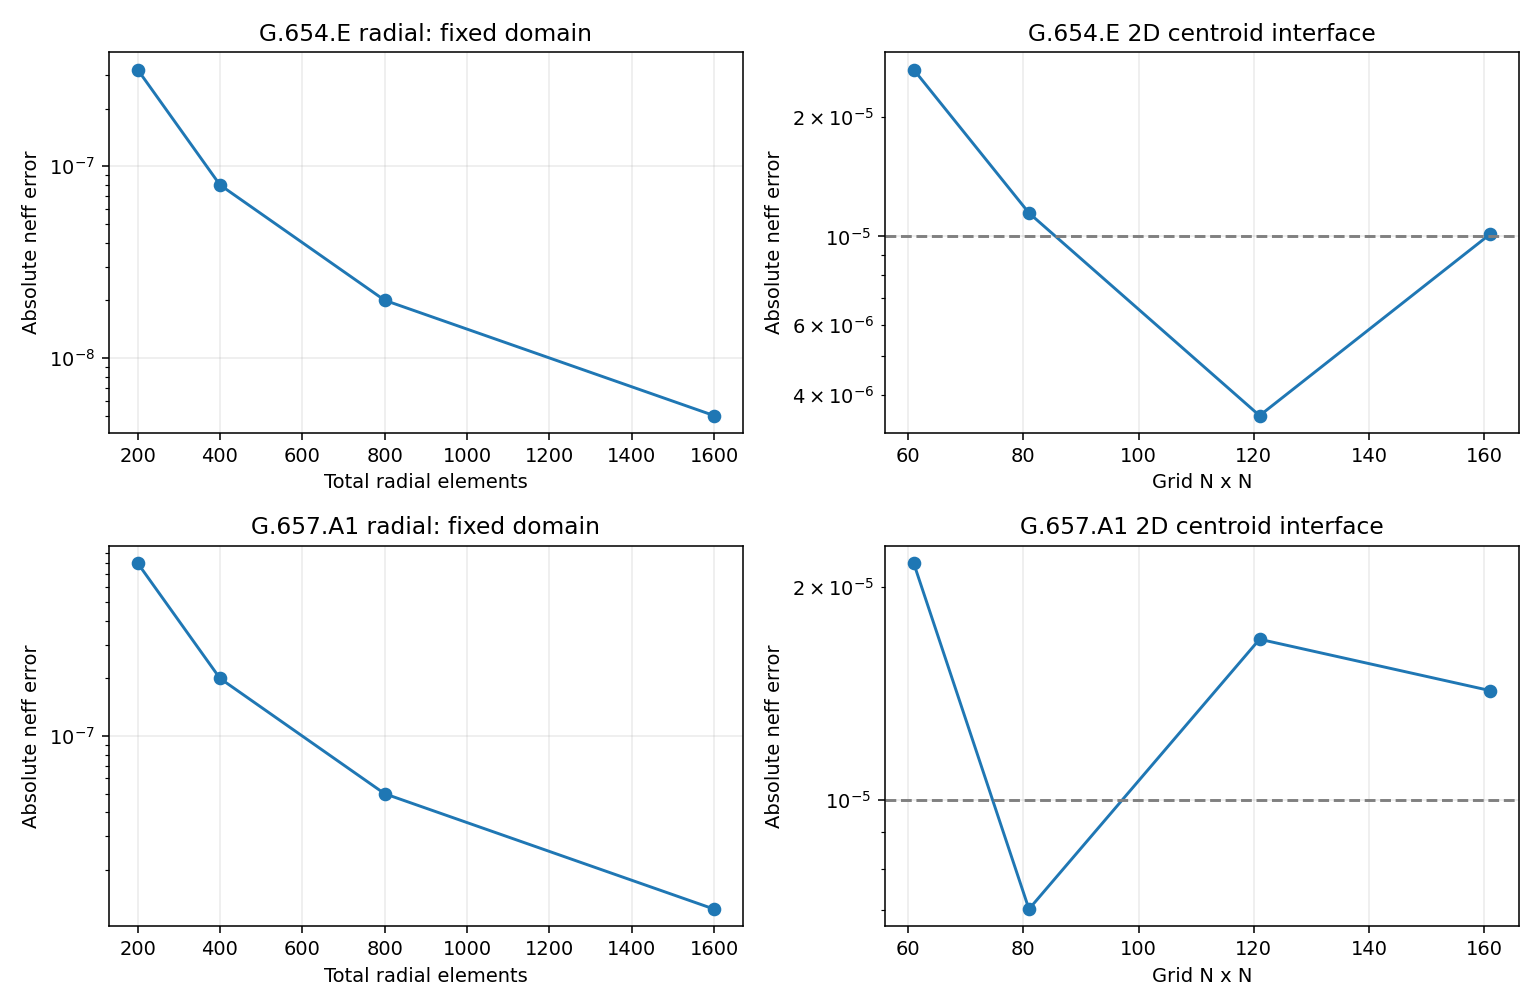

In [6]:
# @title 8-1. 두 단면의 실제 FEM 메시 재계산
core_counts=parse_counts(radial_core_mesh_text)
grids=parse_counts(mesh_2d_text,odd=True)
radial_frames=[];cart_frames=[];last_2d={};checks=[]
fig,axs=plt.subplots(2,2,figsize=(11,7.2))
for i,(name,f) in enumerate(fibers.items()):
    rad,cart,last=mesh_study(f,core_counts,int(cladding_to_core_element_ratio),grids,box_2d_halfwidth_um,run_2d_fem)
    radial_frames.append(rad.assign(fiber=name));last_2d[name]=last
    display(rad.assign(fiber=name))
    axs[i,0].semilogy(rad.total_elements,rad.neff_abs_error,'o-');axs[i,0].set(title=name+' radial: fixed domain',xlabel='Total radial elements',ylabel='Absolute neff error')
    rr=rad.iloc[-1]
    checks.extend([dict(fiber=name,test='radial |neff error| <1e-6',passed=bool(rr.neff_abs_error<1e-6)),dict(fiber=name,test='radial |Aeff error| <1%',passed=bool(abs(rr.Aeff_error_pct)<1))])
    if len(cart):
        cart_frames.append(cart.assign(fiber=name));display(cart.assign(fiber=name))
        axs[i,1].semilogy(cart.grid_n,cart.neff_abs_error,'o-');axs[i,1].axhline(1e-5,color='gray',ls='--')
        axs[i,1].set(title=name+' 2D centroid interface',xlabel='Grid N x N',ylabel='Absolute neff error')
        checks.append(dict(fiber=name,test='2D |neff error| <1e-5',passed=bool(cart.iloc[-1].neff_abs_error<1e-5)))
    else:axs[i,1].text(.1,.5,'2D FEM disabled',transform=axs[i,1].transAxes)
for ax in axs.flat:ax.grid(alpha=.25)
fig.tight_layout();fig.savefig(RESULT_DIR/'01_Mesh_Comparison.png',dpi=140);plt.show()
radial_df=pd.concat(radial_frames,ignore_index=True)
cartesian_df=pd.concat(cart_frames,ignore_index=True) if cart_frames else pd.DataFrame()


<Figure size 1000x450 with 4 Axes>

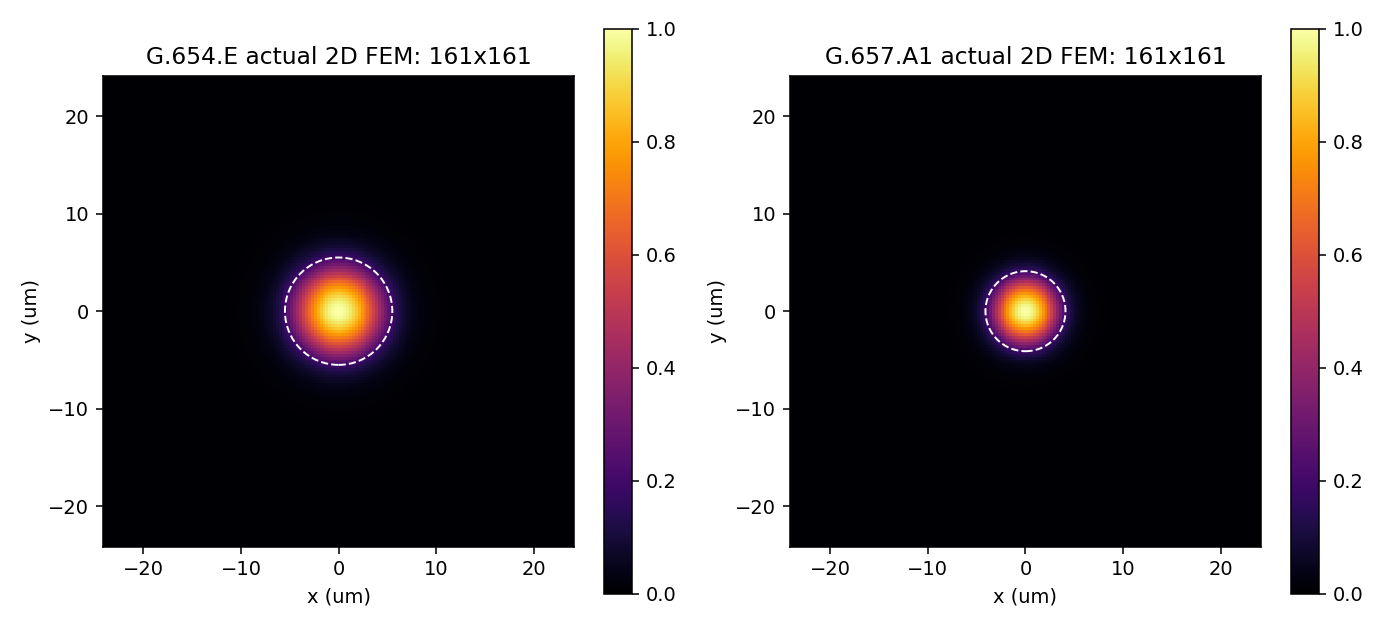

In [7]:
# @title 8-2. 실제 2D FEM 세기 분포 (2D 계산을 켠 경우)
if run_2d_fem:
    fig,axs=plt.subplots(1,2,figsize=(10,4.5))
    for ax,(name,s) in zip(axs,last_2d.items()):
        n=s['n'];xy=s['xy'];I=s['fields'][:,0].reshape(n,n)**2
        im=ax.pcolormesh(xy[:,0].reshape(n,n),xy[:,1].reshape(n,n),I/I.max(),shading='auto',cmap='inferno')
        ax.add_patch(plt.Circle((0,0),s['fiber'].radius_um,fill=False,edgecolor='white',ls='--'))
        ax.set(title=name+f' actual 2D FEM: {n}x{n}',xlabel='x (um)',ylabel='y (um)',aspect='equal');fig.colorbar(im,ax=ax)
    fig.tight_layout();fig.savefig(RESULT_DIR/'02_Actual_2D_Fields.png',dpi=140);plt.show()


## 9. 계산영역 크기 검사 — Mesh 간격 유지

외부 경계가 너무 가까우면 장의 꼬리를 잘라 오차를 만듭니다. 코어 요소 수를 고정하고 클래딩 간격을 약 0.04 µm로 유지하면서 외곽 반경을 바꿉니다. 이것은 Mesh 세분화 검사와 별개입니다.


In [8]:
# @title 9-1. Radial 외곽 반경 30/40/50 um 비교
domain_frames=[]
for name,f in fibers.items():
    d=domain_study(f,core_elements=max(core_counts))
    domain_frames.append(d.assign(fiber=name));display(d.assign(fiber=name))
    checks.append(dict(fiber=name,test='domain last neff change <1e-7',passed=bool(abs(d.iloc[-1].neff-d.iloc[-2].neff)<1e-7)))
domain_df=pd.concat(domain_frames,ignore_index=True)


   outer_radius_um  core_elements  ...      residual    fiber
0             30.0            320  ...  3.601330e-14  G.654.E
1             40.0            320  ...  3.350060e-14  G.654.E
2             50.0            320  ...  3.933197e-14  G.654.E

[3 rows x 9 columns]

   outer_radius_um  core_elements  ...      residual     fiber
0             30.0            320  ...  3.889334e-14  G.657.A1
1             40.0            320  ...  4.197832e-14  G.657.A1
2             50.0            320  ...  3.809950e-14  G.657.A1

[3 rows x 9 columns]

<Figure size 1300x380 with 3 Axes>

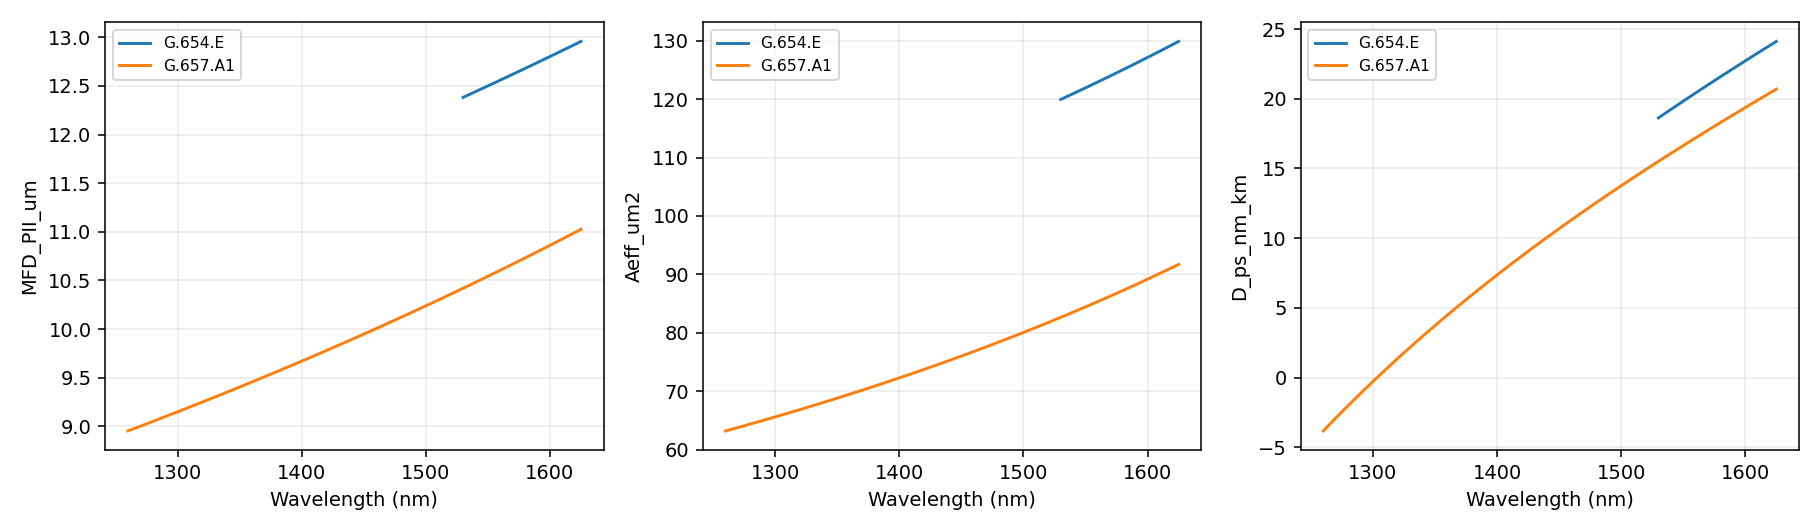

In [9]:
# @title 10. 파장별 MFD / Aeff / D 예측
spectra=[];fig,axs=plt.subplots(1,3,figsize=(13,3.8))
for name,f in fibers.items():
    lo,hi=(1530,1625) if name=='G.654.E' else (1260,1625)
    rows=[]
    for wl in np.linspace(lo,hi,45):
        ff=replace(f,wavelength_um=wl/1000);mm=radial_lp01_aeff(ff)
        rows.append(dict(fiber=name,wavelength_nm=float(wl),MFD_PII_um=mm['MFD_petermann_ii_um'],Aeff_um2=mm['Aeff_um2'],D_ps_nm_km=dispersion_lp01(ff)))
    d=pd.DataFrame(rows);spectra.append(d)
    for ax,y in zip(axs,['MFD_PII_um','Aeff_um2','D_ps_nm_km']):ax.plot(d.wavelength_nm,d[y],label=name);ax.set(xlabel='Wavelength (nm)',ylabel=y);ax.grid(alpha=.25);ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(RESULT_DIR/'03_Spectral_Outputs.png',dpi=140);plt.show()
spectrum_df=pd.concat(spectra,ignore_index=True)


## 11. 결과의 의미와 사용 제한

- Δn 직접 입력 모드: MFD는 모델 출력입니다. MFD 보정 모드: 목표 MFD와 일치하는 것은 보정의 결과입니다.
- 코어 반경·Δn은 제품 이름만으로 결정되지 않습니다. 같은 MFD를 만족하는 여러 가상 단면이 나옵니다.
- 원형 경계 정합 FEM과 기존 2D 중심점 분류 방식은 기하 오차가 다릅니다. 2D 오차가 Mesh에 대해 비단조적일 수 있습니다.
- 스칼라 근사, 파장에 대해 일정한 Δn, 유한 계산영역의 영향이 있습니다. 실제 제품·굽힘 손실·전체 벡터 해석 정확도를 이 결과만으로 주장하지 않습니다.
- MFD_PII와 MFD_2nd는 정의가 다릅니다. Aeff를 단순히 pi*(MFD/2)^2로 바꾸지 않습니다.

원본 제품별 실행 보고서: [G.654.E](https://github.com/kimheeseo/LSCNS/tree/main/COMSOL/g654e_validation) · [G.657.A1](https://github.com/kimheeseo/LSCNS/tree/main/COMSOL/g657a1_validation)


In [10]:
# @title 12. 입력·출력·예시·검증 결과 저장 및 ZIP
checks_df=pd.DataFrame(checks);display(checks_df)
print('이 수치 판정은 같은 가상 단면의 해석해 대비 결과입니다. FAIL은 그대로 저장합니다.')
frames={'current_inputs.csv':input_df.reset_index(names='fiber'),'current_outputs.csv':current_df,'example_inputs_outputs.csv':examples_df,
 'radial_mesh.csv':radial_df,'radial_domain.csv':domain_df,'spectral_outputs.csv':spectrum_df,'checks.csv':checks_df}
if len(cartesian_df):frames['cartesian_mesh.csv']=cartesian_df
for filename,df in frames.items():df.to_csv(RESULT_DIR/filename,index=False)
def records(df):return json.loads(df.to_json(orient='records',double_precision=15))
record=dict(schema_version=1,model='ideal circular step-index weak-guidance scalar LP01',
 MFD_fit_enabled=fit_delta_n_from_mfd,current_inputs=configs,current_outputs=records(current_df),examples=records(examples_df),
 numerical_checks=records(checks_df),passed=int(checks_df.passed.sum()),total=len(checks_df),
 radial_mesh=records(radial_df),cartesian_mesh=records(cartesian_df),radial_domain=records(domain_df),
 mesh_inputs=dict(radial_core_counts=core_counts,clad_ratio=cladding_to_core_element_ratio,radial_outer_radius_um=radial_outer_radius_um,grid_counts=grids,box_halfwidth_um=box_2d_halfwidth_um,run_2d=run_2d_fem),
 environment=dict(python=sys.version,numpy=np.__version__,scipy=scipy.__version__,pandas=pd.__version__,matplotlib=plt.matplotlib.__version__,platform=platform.platform()),
 not_computed=['actual attenuation','bending loss','measured cable cutoff','PMD/birefringence','BER/reach','full-vector Maxwell equivalence'])
(RESULT_DIR/'summary.json').write_text(json.dumps(record,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
report='# 입력/출력 실제 실행 보고서\n\n'
for x in record['current_outputs']:
    report+=f"- {x['fiber']}: analysis={x['analysis_wavelength_nm']} nm, a={x['assumed_radius_um']} um, Delta n={x['delta_n']:.10f}, Aeff={x['Aeff_um2']:.5f} um2, D={x['D_ps_nm_km']:.5f} ps/(nm km)\n"
report+=f"\nNumerical checks: {record['passed']}/{record['total']} PASS; failures preserved. Calibration is not independent product validation.\n"
(RESULT_DIR/'EXECUTION_REPORT.md').write_text(report,encoding='utf-8')
archive=Path('Fiber_Input_Output_Results.zip')
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for file in sorted(RESULT_DIR.iterdir()):
        if file.is_file():z.write(file,arcname='Fiber_Input_Output_Results/'+file.name)
display(FileLink(str(archive)));print('현재 실행에서 만든 파일만 ZIP에 포함:',archive)
# from google.colab import files
# files.download(str(archive))


이 수치 판정은 같은 가상 단면의 해석해 대비 결과입니다. FAIL은 그대로 저장합니다.
현재 실행에서 만든 파일만 ZIP에 포함: Fiber_Input_Output_Results.zip


      fiber                           test  passed
0   G.654.E      radial |neff error| <1e-6    True
1   G.654.E        radial |Aeff error| <1%    True
2   G.654.E          2D |neff error| <1e-5   False
3  G.657.A1      radial |neff error| <1e-6    True
4  G.657.A1        radial |Aeff error| <1%    True
5  G.657.A1          2D |neff error| <1e-5   False
6   G.654.E  domain last neff change <1e-7    True
7  G.657.A1  domain last neff change <1e-7    True

/workspace/scratch/2a1494642f29/repo/COMSOL/fiber_simulation_guide/Fiber_Input_Output_Results.zip